# Analisis Eksplorasi Data (EDA): Statistik Pemain Understat (2023-2025)

Dataset ini mencakup data performa pemain dari tiga kompetisi (EPL, La Liga, Serie A) pada musim 2023/2024, 2024/2025, dan 2025/2026.


---
### Pengumpulan Data (Web Scraping):
Proses scraping pada proyek ini diimplementasikan dalam skrip `webscrap.py` menggunakan **Network Reverse Engineering** langsung ke endpoint AJAX internal Understat (`/getLeagueData/{league}/{season}`).
- **Tools yang Digunakan:** `requests`, `pandas`, `pathlib` (dikelola melalui `uv`).
- **Alasan Tidak Menggunakan BeautifulSoup:** Halaman Understat menggunakan *client-side dynamic rendering* via JavaScript sehingga data tabel tidak berada di tag HTML statis awal. Dengan menembak langsung endpoint AJAX internal via `requests`, data diterima langsung dalam format JSON terstruktur murni (`res.json()`), jauh lebih cepat, stabil, dan tanpa *overhead* parsing HTML DOM maupun browser automation.

## Data Dictionary

Berikut definisi operasional seluruh variabel mentah dan metrik turunan yang digunakan dalam analisis ini:

### 1. Fitur Mentah (19 Kolom dari Understat)

| Nama Kolom | Tipe Data | Definisi |
|---|---|---|
| `id` | Integer | ID unik pemain di sistem basis data Understat. |
| `player_name` | String | Nama lengkap pemain. |
| `position` | String | Posisi bermain pemain di lapangan (F, M, D, GK, S, dan kombinasinya). |
| `team_title` | String | Klub yang dibela pemain pada musim tersebut (berganti klub digabung dengan koma). |
| `league` | String | Nama kompetisi liga (`EPL`, `La_liga`, `Serie_A`). |
| `games` | Integer | Total pertandingan yang dimainkan (starter maupun pemain pengganti). |
| `time` | Integer | Total durasi menit bermain di lapangan sepanjang musim. |
| `goals` | Integer | Jumlah gol aktual yang dicetak (termasuk penalti; gol bunuh diri lawan tidak dihitung). |
| `xG` | Float | *Expected Goals*. Probabilitas statistik (skala 0–1 per tembakan) bahwa peluang menghasilkan gol berdasarkan posisi, sudut, tipe umpan, dan situasi laga. |
| `npg` | Integer | *Non-Penalty Goals*. Jumlah gol aktual murni di luar eksekusi penalti (`goals - gol_penalti`). |
| `npxG` | Float | *Non-Penalty Expected Goals*. Total xG dengan mengecualikan seluruh peluang penalti (mengukur ketajaman murni *open play* / bola mati non-penalti). |
| `assists` | Integer | Jumlah umpan aktual yang langsung diselesaikan menjadi gol oleh rekan setim. |
| `xA` | Float | *Expected Assists*. Probabilitas bahwa umpan yang dilepaskan berbuah menjadi gol, terlepas dari apakah rekan setim berhasil mencetak gol atau tidak. |
| `shots` | Integer | Total percobaan tembakan (tepat sasaran, melenceng, maupun diblok). |
| `key_passes` | Integer | Umpan kunci, yaitu umpan yang langsung menghasilkan percobaan tembakan oleh rekan setim. |
| `yellow_cards` | Integer | Akumulasi kartu kuning sepanjang musim. |
| `red_cards` | Integer | Akumulasi kartu merah sepanjang musim (langsung maupun 2 kartu kuning). |
| `xGChain` | Float | Total xG dari seluruh rangkaian penguasaan bola yang berujung tembakan di mana pemain ikut terlibat dalam alur serangan. |
| `xGBuildup` | Float | Total xG dari rangkaian serangan yang melibatkan pemain, **dengan mengecualikan** tembakan dan umpan kunci langsung dari pemain tersebut (murni fase persiapan serangan). |

**Kode Posisi (`position`):**
- `GK`: *Goalkeeper* (Kiper)
- `D`: *Defender* (Bek/Pemain Belakang)
- `M`: *Midfielder* (Gelandang)
- `F`: *Forward* (Penyerang)
- `S`: *Substitute* (Pemain Pengganti/Cadangan)
- *Kombinasi*: Menunjukkan pemain multi-posisi atau rotasi (contoh: `F S` penyerang cadangan, `F M S` penyerang/gelandang serang rotasi, `D M` bek yang juga bermain gelandang).

---

### 2. Fitur Tambahan (Engineered Features pada Analisis)

| Nama Metrik | Rumus | Tujuan Analisis |
|---|---|---|
| `season` | Label string (contoh: `'2023/2024'`) | Pembeda musim kompetisi saat ketiga dataset digabungkan. |
| `xG90` | `(xG / time) * 90` | Expected goals per 90 menit (menghilangkan bias menit bermain). |
| `xA90` | `(xA / time) * 90` | Expected assists per 90 menit. |
| `shots90` | `(shots / time) * 90` | Frekuensi tembakan per 90 menit. |
| `npxG90` | `(npxG / time) * 90` | Expected goals non-penalti per 90 menit. |
| `npxG_xA90` | `npxG90 + xA90` | Total ancaman serangan non-penalti per 90 menit. |
| `xg_per_shot` | `xG / shots` | Kualitas rata-rata peluang per tembakan (selektif vs spekulatif). |
| `buildup_ratio` | `xGBuildup / xGChain` | Rasio keterlibatan build-up (rendah = *poacher*, tinggi = *playmaking forward*). |
| `goals - xG` | `goals - xG` | Selisih efisiensi penyelesaian untuk uji regresi ke rerata (*regression to the mean*). |

In [14]:
import os
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

data_dir = Path('data') if Path('data').exists() else Path('.')

# data per musim
df_2023 = pd.read_csv(data_dir / 'understat_players_xg_2023.csv')
df_2024 = pd.read_csv(data_dir / 'understat_players_xg_2024.csv')
df_2025 = pd.read_csv(data_dir / 'understat_players_xg_2025.csv')

df_2023['season'] = '2023/2024'
df_2024['season'] = '2024/2025'
df_2025['season'] = '2025/2026'

# concat seluruh musim
df = pd.concat([df_2023, df_2024, df_2025], ignore_index=True)

print(f"Total baris: {len(df)}")
print(f"Total kolom: {len(df.columns)}")
print(f"Jumlah missing values: {df.isnull().sum().sum()}")
print(f"Jumlah pemain unik: {df['player_name'].nunique()}") 
print(f"Jumlah data duplikat: {df.duplicated().sum()}")
df.head()

Total baris: 5232
Total kolom: 20
Jumlah missing values: 0
Jumlah pemain unik: 2812
Jumlah data duplikat: 0


,id,player_name,position,team_title,league,games,time,goals,xG,npg,npxG,assists,xA,shots,key_passes,yellow_cards,red_cards,xGChain,xGBuildup,season
0,8260,Erling Haaland,F S,Manchester City,EPL,31,2581,27,31.653997,20,25.564646,5,4.751756,122,29,1,0,30.197254,3.128645,2023/2024
1,8497,Cole Palmer,F M S,"Chelsea,Manchester City",EPL,34,2640,22,17.832245,13,10.981725,11,11.869294,108,72,7,0,31.036520,15.302413,2023/2024
2,5232,Alexander Isak,F S,Newcastle United,EPL,30,2305,21,22.074266,16,17.507253,2,3.652040,78,27,1,0,24.041152,5.754798,2023/2024
3,1679,Dominic Solanke,F S,Bournemouth,EPL,38,3346,19,21.406831,17,19.123324,3,3.543750,109,39,3,0,22.588012,4.080138,2023/2024
4,6055,Phil Foden,F M S,Manchester City,EPL,35,2895,19,11.307983,19,11.307983,8,8.516233,105,73,2,0,30.416967,16.998998,2023/2024


<Figure size 400x500 with 0 Axes>

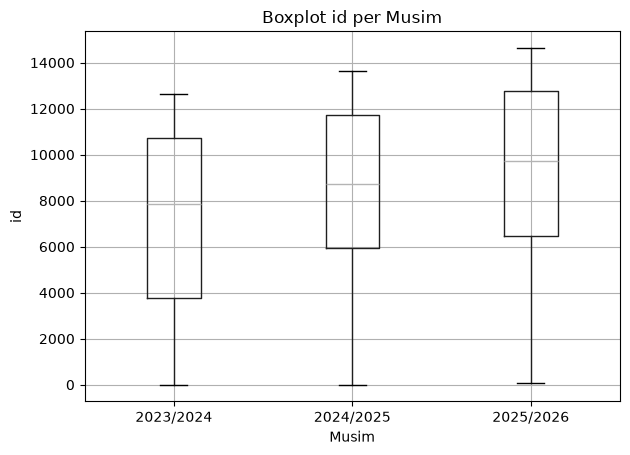

<Figure size 400x500 with 0 Axes>

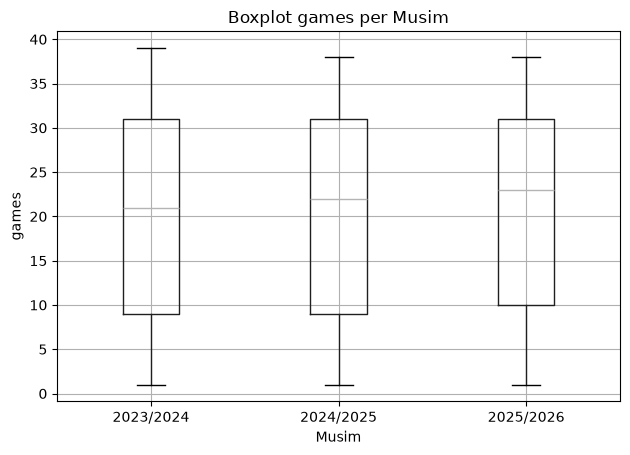

<Figure size 400x500 with 0 Axes>

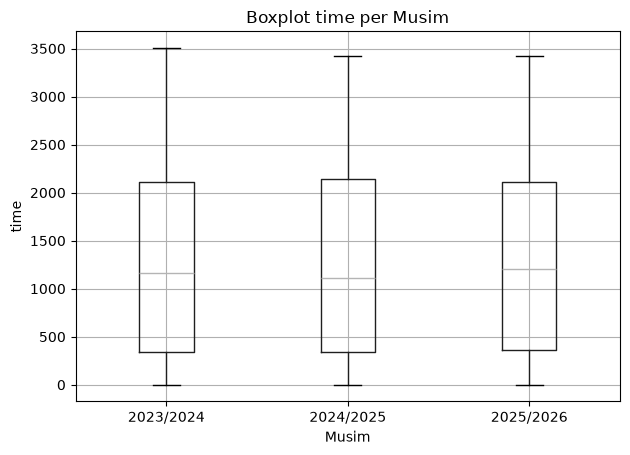

<Figure size 400x500 with 0 Axes>

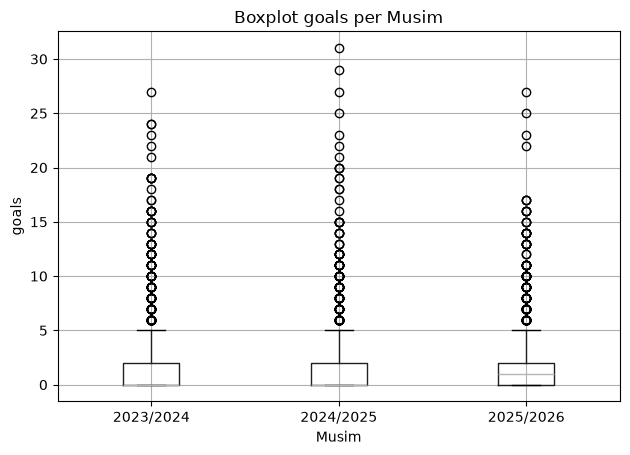

<Figure size 400x500 with 0 Axes>

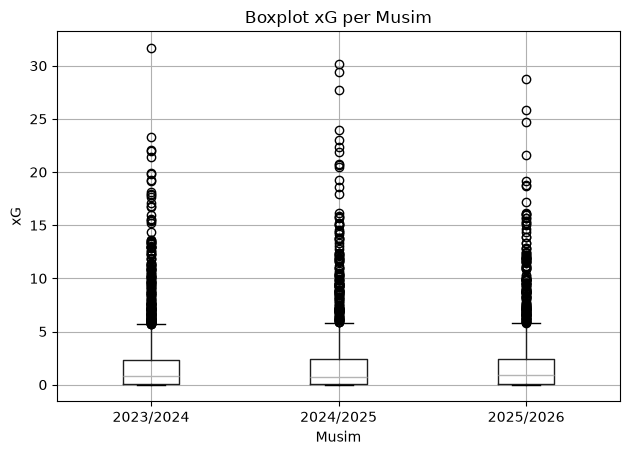

<Figure size 400x500 with 0 Axes>

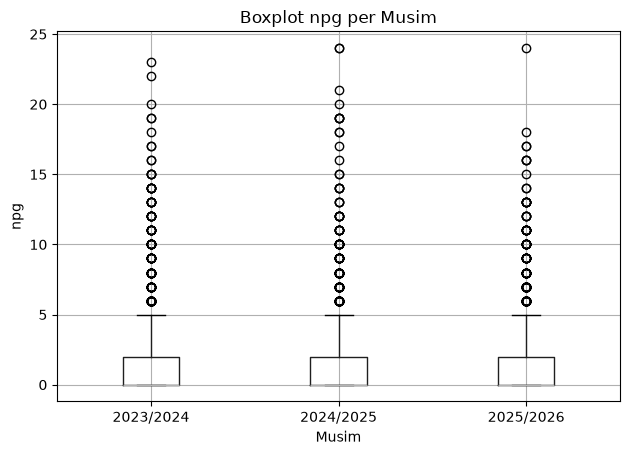

<Figure size 400x500 with 0 Axes>

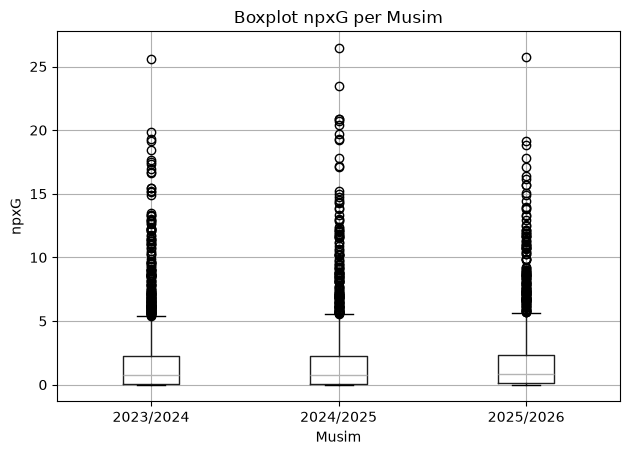

<Figure size 400x500 with 0 Axes>

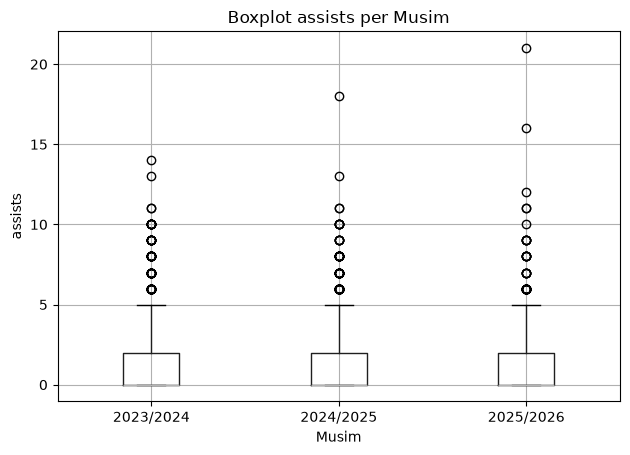

<Figure size 400x500 with 0 Axes>

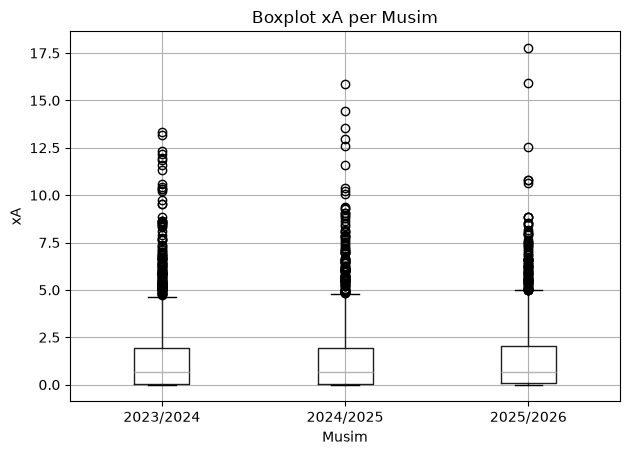

<Figure size 400x500 with 0 Axes>

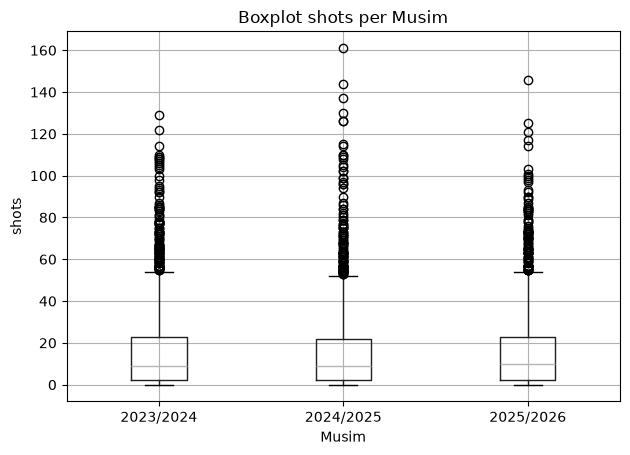

<Figure size 400x500 with 0 Axes>

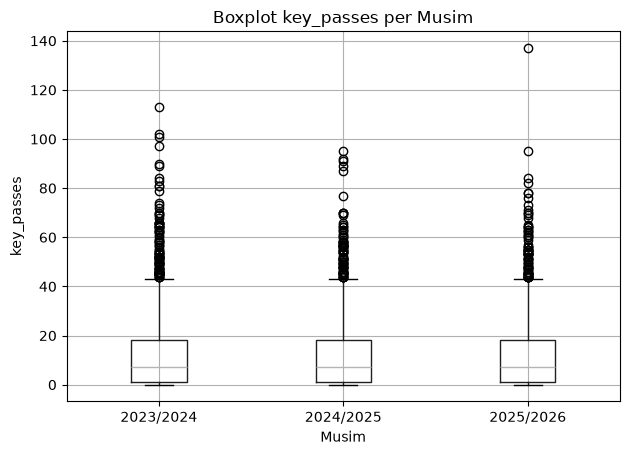

<Figure size 400x500 with 0 Axes>

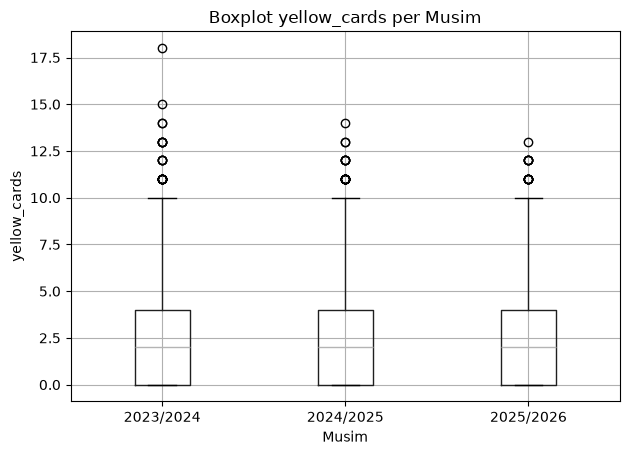

<Figure size 400x500 with 0 Axes>

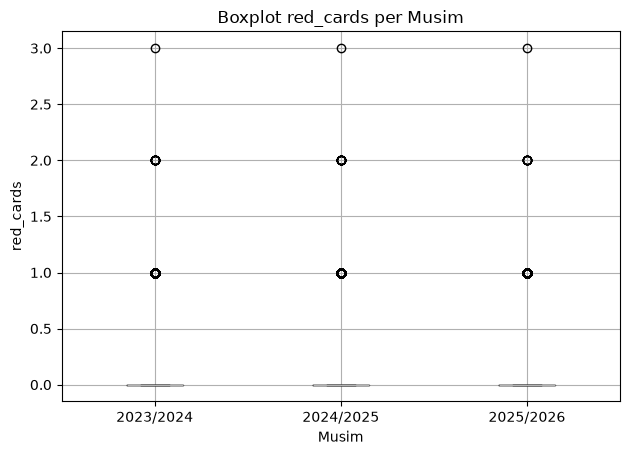

<Figure size 400x500 with 0 Axes>

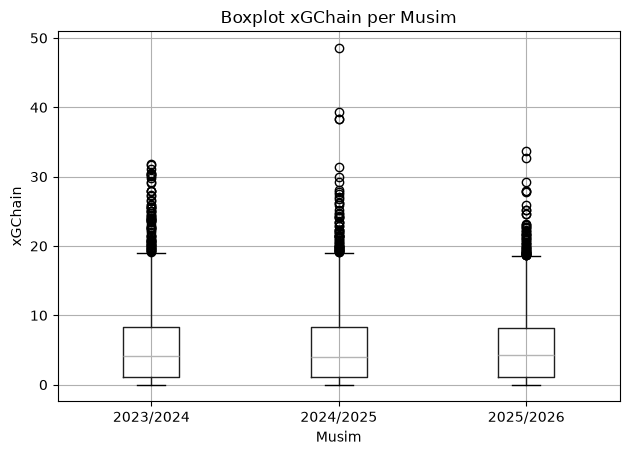

<Figure size 400x500 with 0 Axes>

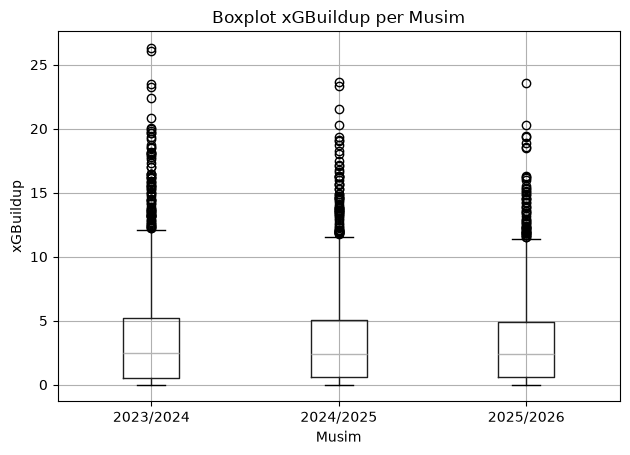

In [15]:
## boxplot semua kolom
for col in df.select_dtypes(include=[np.number]).columns:
    plt.figure(figsize=(4,5))
    df.boxplot(column=col, by='season')
    plt.title(f'Boxplot {col} per Musim')
    plt.suptitle('')  # Hapus judul default
    plt.xlabel('Musim')
    plt.ylabel(col)
    plt.tight_layout()
    plt.show()
    

In [16]:
## cek xg outlier siapa
display(df[df['xG'] > df['xG'].quantile(0.999)][['player_name', 'season', 'team_title', 'xG']].sort_values(by='xG', ascending=False))

## cek xgchain outlier siapa
display(df[df['xGChain'] > df['xGChain'].quantile(0.999)][['player_name', 'season', 'team_title', 'xGChain']].sort_values(by='xGChain', ascending=False))

,player_name,season,team_title,xG
0,Erling Haaland,2023/2024,Manchester City,31.653997
2320,Kylian Mbappe-Lottin,2024/2025,Real Madrid,30.135636
2321,Robert Lewandowski,2024/2025,Barcelona,29.414339
3509,Erling Haaland,2025/2026,Manchester City,28.795336
1758,Mohamed Salah,2024/2025,Liverpool,27.706267
4046,Kylian Mbappe-Lottin,2025/2026,Real Madrid,25.796529


,player_name,season,team_title,xGChain
1758,Mohamed Salah,2024/2025,Liverpool,48.535889
2325,Raphinha,2024/2025,Barcelona,39.282579
2320,Kylian Mbappe-Lottin,2024/2025,Real Madrid,38.313464
2345,Lamine Yamal,2024/2025,Barcelona,38.307875
4051,Lamine Yamal,2025/2026,Barcelona,33.655128
3509,Erling Haaland,2025/2026,Manchester City,32.735353


In [17]:
## keypass outlier
display(df[df['key_passes'] > df['key_passes'].quantile(0.999)][['player_name', 'season', 'team_title', 'key_passes']].sort_values(by='key_passes', ascending=False))

,player_name,season,team_title,key_passes
3530,Bruno Fernandes,2025/2026,Manchester United,137
24,Bruno Fernandes,2023/2024,Manchester United,113
37,Martin Odegaard,2023/2024,Arsenal,102
87,Pascal Groß,2023/2024,Brighton,101
622,Ilkay Gündogan,2023/2024,Barcelona,97


### missing values or duplicate data !?

gaada missing values dan dupllikat, ayo langsung analisis

### how about outlier !??

xg outlier pemain-pemain elite semua, bukan error. emang jago

## 1. Normalisasi Metrik per 90 Menit

Penjumlahan total gol atau xG bias terhadap pemain yang memiliki menit bermain tinggi. Untuk membandingkan efisiensi murni antar-pemain, statistik dinormalisasi ke satuan 90 menit dengan filter batas minimum bermain 900 menit (setara 10 pertandingan penuh) guna mengurangi noise dari sampel kecil.

Metrik utama yang dihitung:
- `xG90`: Expected goals per 90 menit.
- `xA90`: Expected assists per 90 menit.
- `npxG_xA90`: Non-penalty xG + xA per 90 menit (total ancaman non-penalti).

,player_name,season,team_title,league,time,npxG_xA90,npxG90,xA90
2323,Alexander Sørloth,2024/2025,Atletico Madrid,La_liga,1525,1.24,1.16,0.08
2338,Ferrán Torres,2024/2025,Barcelona,La_liga,1093,1.09,0.80,0.29
21,Darwin Núñez,2023/2024,Liverpool,EPL,2037,1.08,0.81,0.26
88,Kevin De Bruyne,2023/2024,Manchester City,EPL,1233,1.06,0.19,0.87
0,Erling Haaland,2023/2024,Manchester City,EPL,2581,1.06,0.89,0.17
1268,Aleksey Miranchuk,2023/2024,Atalanta,Serie_A,1168,1.03,0.62,0.41
6,Mohamed Salah,2023/2024,Liverpool,EPL,2556,1.02,0.58,0.43
1815,Bukayo Saka,2024/2025,Arsenal,EPL,1763,1.01,0.42,0.59
2320,Kylian Mbappe-Lottin,2024/2025,Real Madrid,La_liga,2938,1.01,0.72,0.29
2325,Raphinha,2024/2025,Barcelona,La_liga,2862,0.98,0.56,0.43


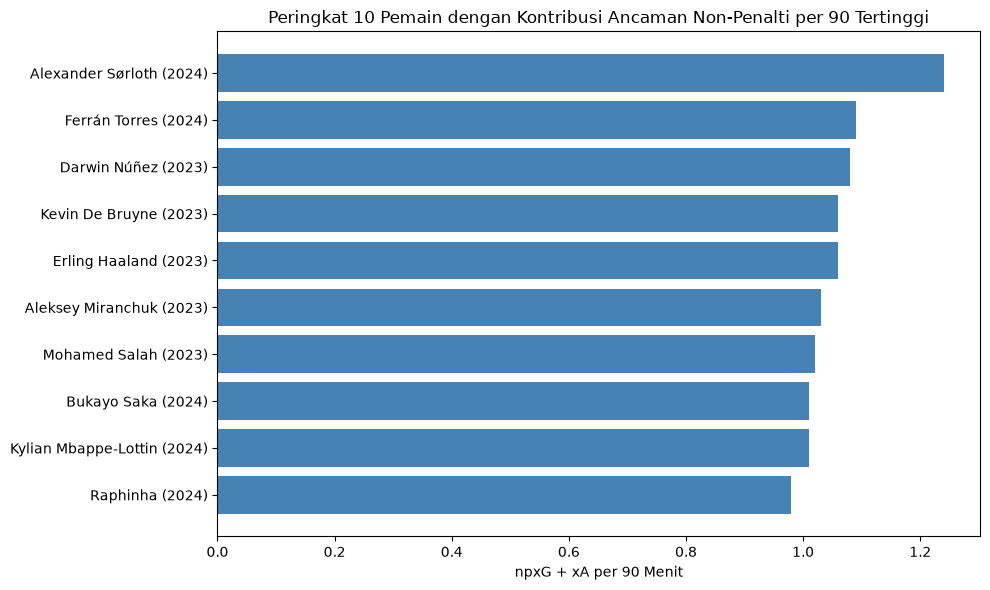

In [18]:
# Filter minimum 900 menit bermain
df_min = df[df['time'] >= 900].copy()

# Perhitungan metrik per 90 menit
df_min['xG90'] = (df_min['xG'] / df_min['time']) * 90
df_min['xA90'] = (df_min['xA'] / df_min['time']) * 90
df_min['shots90'] = (df_min['shots'] / df_min['time']) * 90
df_min['npxG90'] = (df_min['npxG'] / df_min['time']) * 90
df_min['npxG_xA90'] = df_min['npxG90'] + df_min['xA90']
df_min['xg_per_shot'] = df_min['xG'] / df_min['shots'].replace(0, np.nan)
df_min['buildup_ratio'] = df_min['xGBuildup'] / df_min['xGChain'].replace(0, np.nan)

# 10 Pemain dengan ancaman non-penalti per 90 menit tertinggi (seluruh musim)
top_threat = df_min.nlargest(10, 'npxG_xA90')[
    ['player_name', 'season', 'team_title', 'league', 'time', 'npxG_xA90', 'npxG90', 'xA90']
].round(2)

display(top_threat)

# Visualisasi Top 10 npxG + xA per 90
plt.figure(figsize=(10, 6))
labels = [f"{row['player_name']} ({row['season'][:4]})" for _, row in top_threat.iterrows()]
plt.barh(labels[::-1], top_threat['npxG_xA90'][::-1], color='steelblue')
plt.xlabel('npxG + xA per 90 Menit')
plt.title('Peringkat 10 Pemain dengan Kontribusi Ancaman Non-Penalti per 90 Tertinggi')
plt.tight_layout()
plt.savefig('figures/01_top10_ancaman_npxg_xa90.png', dpi=300, bbox_inches='tight')

## 2. Hubungan Kreasi Peluang (xA90) vs. Ancaman Gol (npxG90)

Scatter plot membandingkan kontribusi kreasi peluang (`xA90`) dengan ancaman gol dari permainan terbuka (`npxG90`) per 90 menit bagi pemain dengan durasi bermain minimal 900 menit. Analisis ini mengevaluasi sebaran profil taktis antara pemain spesialis kreator, spesialis penyelesai, dan pemain bertipe *dual-threat*.

5 Pemain dengan Kualitas Tembakan Tertinggi (xG per Tembakan):


,player_name,season,team_title,league,shots,xG,xg_per_shot
3510,Thiago,2025/2026,Brentford,EPL,84,24.690,0.294
30,Callum Wilson,2023/2024,Newcastle United,EPL,35,10.125,0.289
2,Alexander Isak,2023/2024,Newcastle United,EPL,78,22.074,0.283
4685,Jonathan Christian David,2025/2026,Juventus,Serie_A,41,11.464,0.280
4064,Hugo Duro,2025/2026,Valencia,La_liga,36,10.062,0.280


5 Pemain dengan Kualitas Tembakan Terendah (xG per Tembakan):


,player_name,season,team_title,league,shots,xG,xg_per_shot
1246,Ruslan Malinovskiy,2023/2024,Genoa,Serie_A,39,0.985,0.025
764,Unai López,2023/2024,Rayo Vallecano,La_liga,32,0.879,0.027
1083,Lucas Robertone,2023/2024,Almeria,La_liga,37,1.035,0.028
1613,Razvan Marin,2023/2024,Empoli,Serie_A,35,1.008,0.029
4186,Antonio Blanco,2025/2026,Alaves,La_liga,40,1.219,0.030


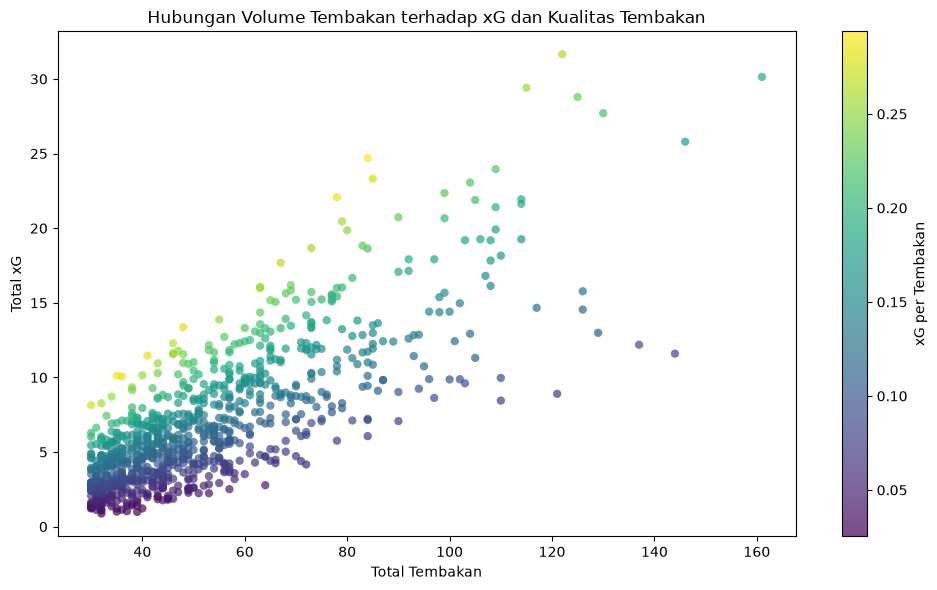

In [19]:
shooters = df_min[df_min['shots'] >= 30].copy()

high_quality = shooters.nlargest(5, 'xg_per_shot')[['player_name', 'season', 'team_title', 'league', 'shots', 'xG', 'xg_per_shot']].round(3)
low_quality = shooters.nsmallest(5, 'xg_per_shot')[['player_name', 'season', 'team_title', 'league', 'shots', 'xG', 'xg_per_shot']].round(3)

print("5 Pemain dengan Kualitas Tembakan Tertinggi (xG per Tembakan):")
display(high_quality)

print("5 Pemain dengan Kualitas Tembakan Terendah (xG per Tembakan):")
display(low_quality)

# ========== Volume tembakan vs Total xG, dengan color encoding kualitas tembakan
plt.figure(figsize=(10, 6))

scatter = plt.scatter(shooters['shots'], shooters['xG'], c=shooters['xg_per_shot'], cmap='viridis', alpha=0.7, edgecolors='none')
plt.colorbar(scatter, label='xG per Tembakan')
plt.xlabel('Total Tembakan')
plt.ylabel('Total xG')
plt.title('Hubungan Volume Tembakan terhadap xG dan Kualitas Tembakan')
plt.tight_layout()

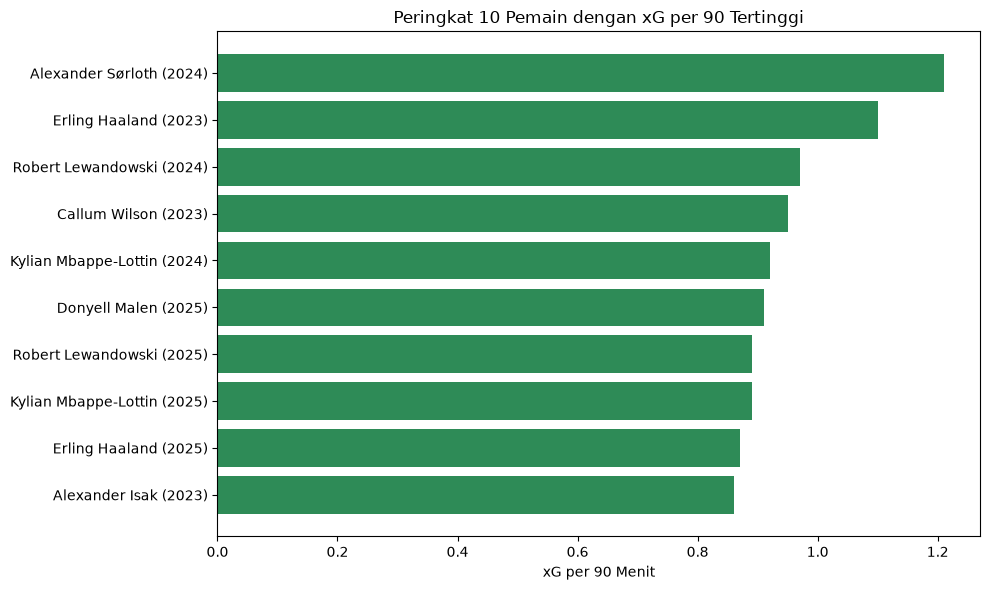

In [20]:
# xg palling banyak 
plt.figure(figsize=(10, 6))
top_xg = df_min.nlargest(10, 'xG90')[['player_name', 'season', 'team_title', 'xG90']].round(2)
plt.barh([f"{row['player_name']} ({row['season'][:4]})" for _, row in top_xg.iterrows()][::-1], top_xg['xG90'][::-1], color='seagreen')
plt.xlabel('xG per 90 Menit')
plt.title('Peringkat 10 Pemain dengan xG per 90 Tertinggi')
plt.tight_layout()

## 3. Keberlanjutan Overperformance Gol (Uji Regresi ke Rerata Lintas 3 Musim)

Overperformance didefinisikan sebagai selisih `goals - xG`. Analisis ini menguji apakah selisih positif yang dicapai seorang pemain bersifat konsisten antar-musim atau mengalami regresi ke rerata.

Pengujian dilakukan pada dua transisi berurutan:
1. Transisi 1: Musim 2023/2024 ke 2024/2025 (n = 647 pemain dengan menit bermain >= 900 di kedua musim).
2. Transisi 2: Musim 2024/2025 ke 2025/2026 (n = 656 pemain dengan menit bermain >= 900 di kedua musim).
3. Pelacakan pemain yang bermain >= 900 menit di ketiga musim (n = 454 pemain).

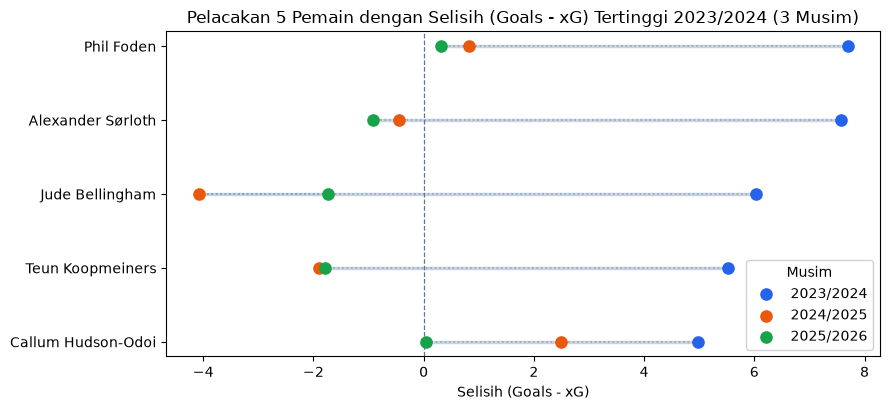

Total pemain dalam kohort 3 musim (>= 900 menit): 454


season,player_name,diff_23,diff_24,diff_25
75,Callum Hudson-Odoi,4.98,2.49,0.05
413,Teun Koopmeiners,5.52,-1.89,-1.79
228,Jude Bellingham,6.03,-4.08,-1.73
25,Alexander Sørloth,7.57,-0.45,-0.93
366,Phil Foden,7.69,0.82,0.31


In [ ]:
import matplotlib.pyplot as plt

# Goals - xG
df_min['diff'] = df_min['goals'] - df_min['xG']

m_all = (
    df_min.pivot_table(index='player_name', columns='season', values='diff')
    .dropna()
    .rename(columns={
        '2023/2024': 'diff_23',
        '2024/2025': 'diff_24',
        '2025/2026': 'diff_25'
    })
    .reset_index()
)

c_23 = '#2563eb'  #  2023/2024
c_24 = '#ea580c'  #  2024/2025
c_25 = '#16a34a'  #  2025/2026

#  5 pemain dengan nilai (Goals - xG) tertinggi pada musim 2023/2024
top5_23 = m_all.nlargest(5, 'diff_23').iloc[::-1].copy()

# dumbbell plot
fig, ax = plt.subplots(figsize=(9, 4.2))

for idx, (_, row) in enumerate(top5_23.iterrows()):
    vals = [row['diff_23'], row['diff_24'], row['diff_25']]

    ax.plot([min(vals), max(vals)], [idx, idx], color='#cbd5e1', linewidth=2.5, zorder=1)
    ax.plot(vals, [idx, idx, idx], color='#94a3b8', linestyle=':', linewidth=1.2, zorder=2)

    ax.scatter(row['diff_23'], idx, color=c_23, s=65, zorder=3, label='2023/2024' if idx == 0 else '')
    ax.scatter(row['diff_24'], idx, color=c_24, s=65, zorder=3, label='2024/2025' if idx == 0 else '')
    ax.scatter(row['diff_25'], idx, color=c_25, s=65, zorder=3, label='2025/2026' if idx == 0 else '')

ax.axvline(0, color='#64748b', linestyle='--', linewidth=0.9)
ax.set_yticks(range(len(top5_23)))
ax.set_yticklabels(top5_23['player_name'])
ax.set_title('Pelacakan 5 Pemain dengan Selisih (Goals - xG) Tertinggi 2023/2024 (3 Musim)')
ax.set_xlabel('Selisih (Goals - xG)')
ax.legend(title='Musim', loc='lower right', framealpha=0.9)

plt.tight_layout()
plt.savefig('figures/03_uji_regresi_ke_rerata.png', dpi=300, bbox_inches='tight')
plt.show()

# ringkasan tabel
print(f"Total pemain dalam kohort 3 musim (>= 900 menit): {len(m_all)}")
display(top5_23[['player_name', 'diff_23', 'diff_24', 'diff_25']].round(2))

## 4. Karakterisasi Peran Penyerang: Poacher vs Playmaking Forward

Metrik Understat membedakan dua tahap keterlibatan:
- `xGChain`: Keterlibatan dalam seluruh urutan penguasaan bola yang berakhir dengan tembakan.
- `xGBuildup`: Keterlibatan dalam urutan penguasaan bola di luar tindakan tembakan dan umpan kunci.

Rasio `xGBuildup / xGChain` pada penyerang (Forward) mengukur seberapa aktif pemain terlibat dalam fase persiapan serangan dibanding hanya menjadi penerima akhir peluang:
- Rasio rendah (< 0.15): *Poacher* / penyerang kotak penalti murni.
- Rasio tinggi (> 0.60): Penyerang yang sering turun ke lini tengah untuk membangun serangan.

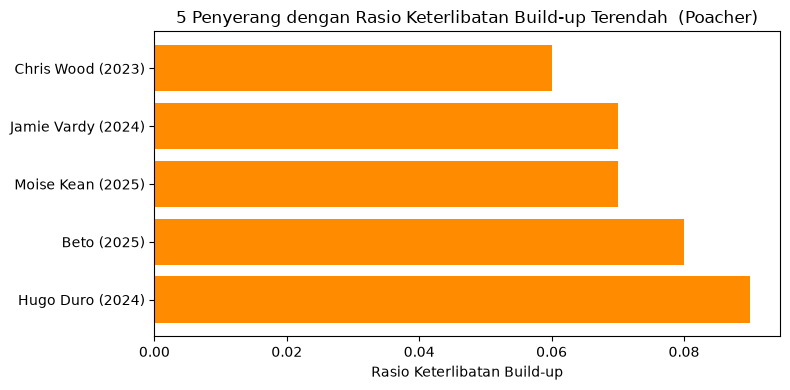

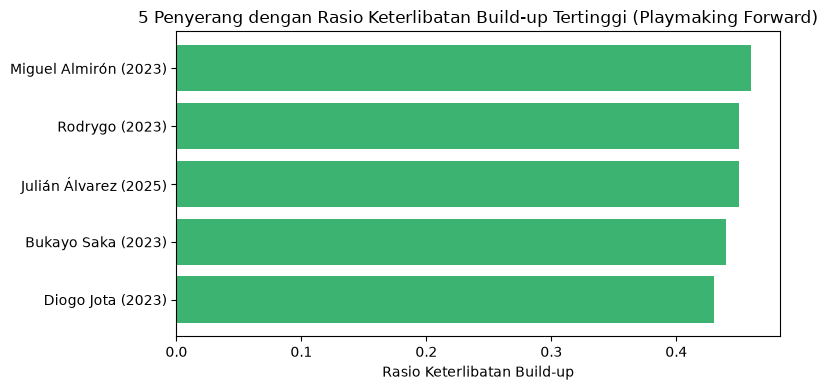

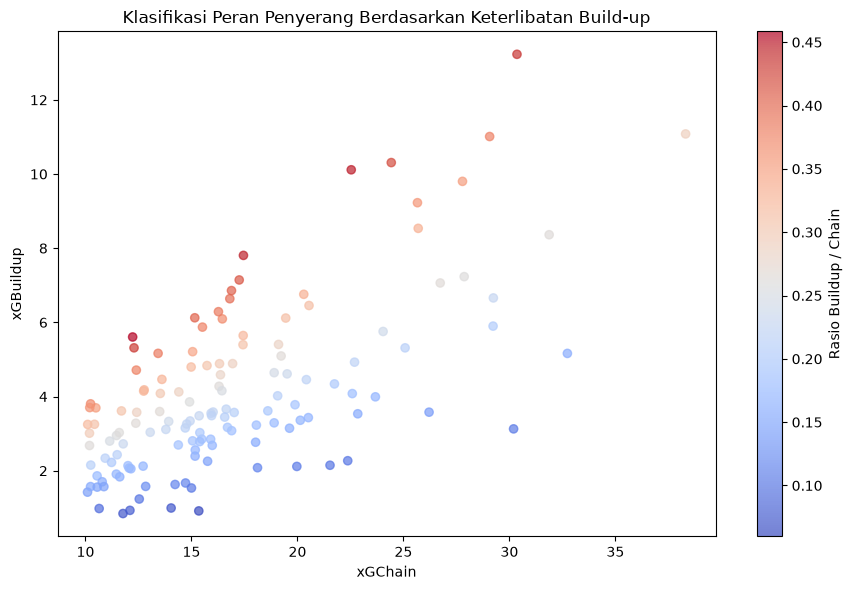

In [ ]:
# Filter posisi forward dengan keterlibatan serangan signifikan (xGChain >= 10 (diambil hanya yg beenr2 forward)
forwards = df_min[
    (df_min['position'].str.contains('F', na=False)) &
    (~df_min['position'].str.contains('D', na=False)) &
    (~df_min['position'].str.contains('M', na=False)) &
    (~df_min['position'].str.contains('W', na=False)) &
    (df_min['xGChain'] >= 10)
].copy()

poachers = forwards.nsmallest(5, 'buildup_ratio')[['player_name', 'season', 'team_title', 'xGChain', 'xGBuildup', 'buildup_ratio']].round(2)
playmaking_fwd = forwards.nlargest(5, 'buildup_ratio')[['player_name', 'season', 'team_title', 'xGChain', 'xGBuildup', 'buildup_ratio']].round(2)

# =========== visualisasi poacher 

plt.figure(figsize=(8, 4))
labels_poacher = [f"{row['player_name']} ({row['season'][:4]})" for _, row in poachers.iterrows()]
plt.barh(labels_poacher[::-1], poachers['buildup_ratio'][::-1], color='darkorange')
plt.xlabel('Rasio Keterlibatan Build-up')
plt.title('5 Penyerang dengan Rasio Keterlibatan Build-up Terendah  (Poacher)')
plt.tight_layout()

# =========== visualisasi playmaking forward (dalam artian sering terlibat dalam build up)
plt.figure(figsize=(8, 4))
labels_playmaking = [f"{row['player_name']} ({row['season'][:4]})" for _, row in playmaking_fwd.iterrows()]
plt.barh(labels_playmaking[::-1], playmaking_fwd['buildup_ratio'][::-1], color='mediumseagreen')
plt.xlabel('Rasio Keterlibatan Build-up')
plt.title('5 Penyerang dengan Rasio Keterlibatan Build-up Tertinggi (Playmaking Forward)')
plt.tight_layout()  


# Scatter plot: xGChain vs xGBuildup
plt.figure(figsize=(9, 6))
plt.scatter(forwards['xGChain'], forwards['xGBuildup'], c=forwards['buildup_ratio'], cmap='coolwarm', alpha=0.7)
plt.colorbar(label='Rasio Buildup / Chain')
plt.xlabel('xGChain')
plt.ylabel('xGBuildup')
plt.title('Klasifikasi Peran Penyerang Berdasarkan Keterlibatan Build-up')

In [ ]:
# valverde
print(df_min[df_min['player_name'].str.contains('Valverde', case=False)][
    ['player_name', 'position', 'season', 'team_title', 'league', 'time', 'xG', 'xA', 'npxG_xA90']
    ].round(2))

            player_name position     season   team_title   league  time    xG  \
710   Federico Valverde      M S  2023/2024  Real Madrid  La_liga  2931  4.20   
2356  Federico Valverde    D M S  2024/2025  Real Madrid  La_liga  3035  2.51   
4109  Federico Valverde  D F M S  2025/2026  Real Madrid  La_liga  2765  2.24   

        xA  npxG_xA90  
710   6.22       0.32  
2356  4.41       0.21  
4109  5.01       0.24  


## 5. Perbandingan Karakteristik Taktik Antar-Liga

Komparasi dilakukan pada metrik rata-rata kualitas tembakan (`xg_per_shot`), frekuensi tembakan per 90 menit (`shots90`), serta tingkat pelanggaran (akumulasi kartu kuning dan merah).

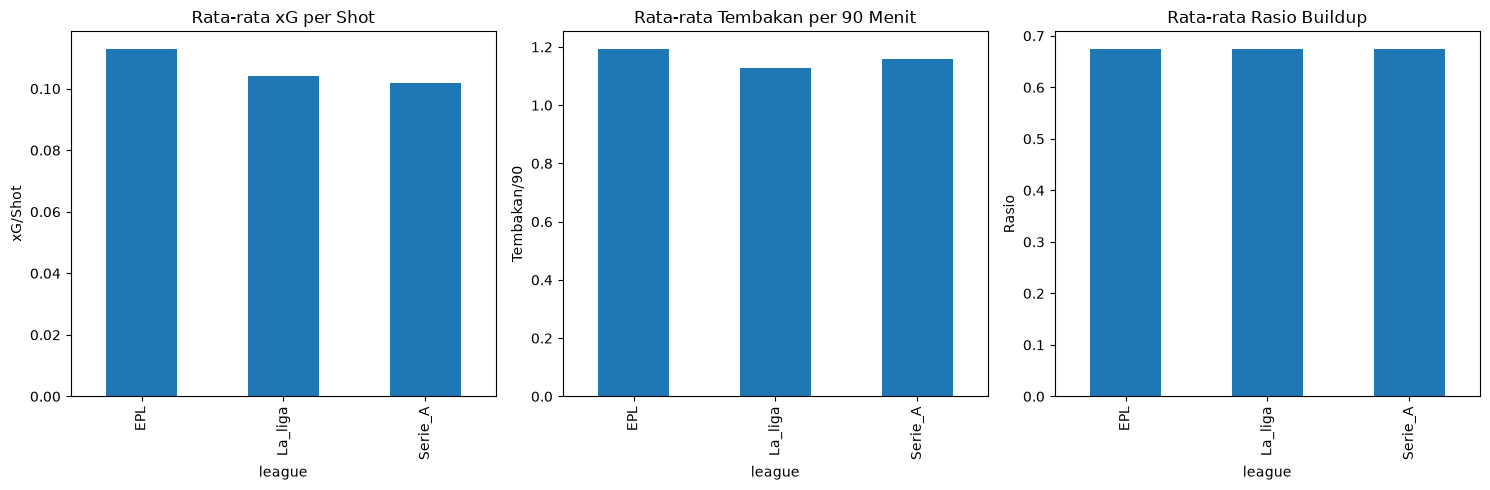

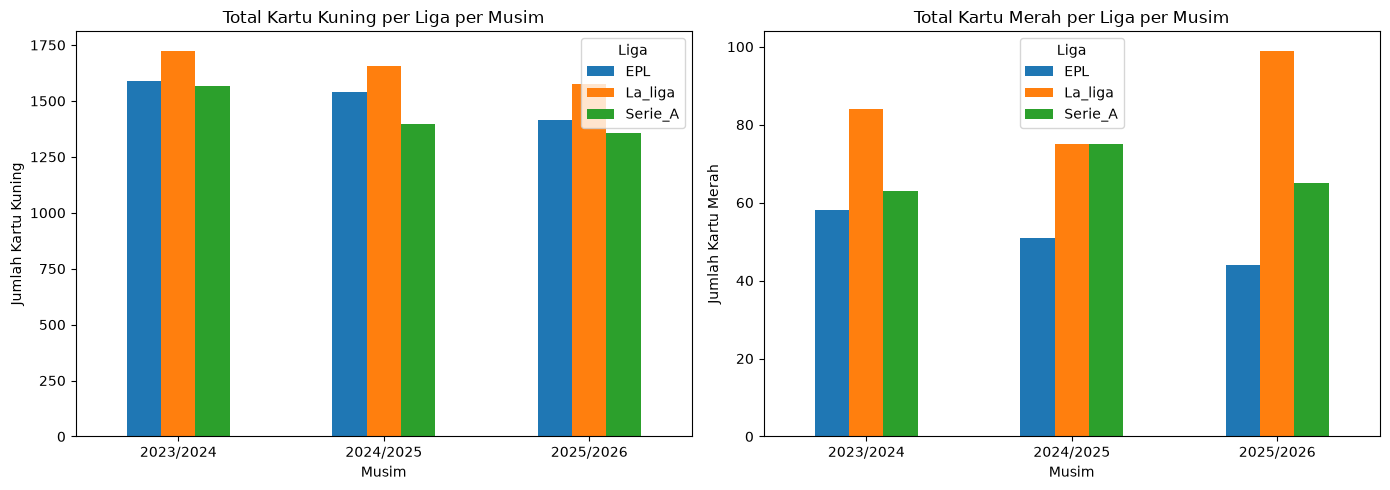

In [ ]:
# Agregasi metrik per liga
league_stats = df_min.groupby('league').agg(
    rata_xg_per_shot=('xg_per_shot', 'mean'),
    rata_shots90=('shots90', 'mean'),
    rata_buildup_ratio=('buildup_ratio', 'mean')
).round(3)

# =========================== visualisasi perbandingan metrik (xg, shots90, buildup_ratio) antar liga
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
league_stats['rata_xg_per_shot'].plot(kind='bar', ax=axes[0])
axes[0].set_title('Rata-rata xG per Shot')
axes[0].set_ylabel('xG/Shot')

league_stats['rata_shots90'].plot(kind='bar', ax=axes[1])
axes[1].set_title('Rata-rata Tembakan per 90 Menit')
axes[1].set_ylabel('Tembakan/90')

league_stats['rata_buildup_ratio'].plot(kind='bar', ax=axes[2])
axes[2].set_title('Rata-rata Rasio Buildup')
axes[2].set_ylabel('Rasio')

plt.tight_layout()
plt.savefig('figures/06_perbandingan_metrik_antar_liga.png', dpi=300, bbox_inches='tight')


# =================== kartu per musim dan liga
cards = df.groupby(['season', 'league'])[['yellow_cards', 'red_cards']].sum()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
cards['yellow_cards'].unstack().plot(kind='bar', ax=axes[0])
axes[0].set_title('Total Kartu Kuning per Liga per Musim')
axes[0].set_xlabel('Musim')
axes[0].set_ylabel('Jumlah Kartu Kuning')
axes[0].tick_params(axis='x', rotation=0)
axes[0].legend(title='Liga')

cards['red_cards'].unstack().plot(kind='bar', ax=axes[1])
axes[1].set_title('Total Kartu Merah per Liga per Musim')
axes[1].set_xlabel('Musim')
axes[1].set_ylabel('Jumlah Kartu Merah')
axes[1].tick_params(axis='x', rotation=0)
axes[1].legend(title='Liga')

plt.tight_layout()

## 6. Matriks Korelasi Metrik (90 menit)
Matriks ini menunjukkan korelasi Pearson antar-metrik performa yang telah dihitung pada data pemain dengan menit bermain $\ge 900$.

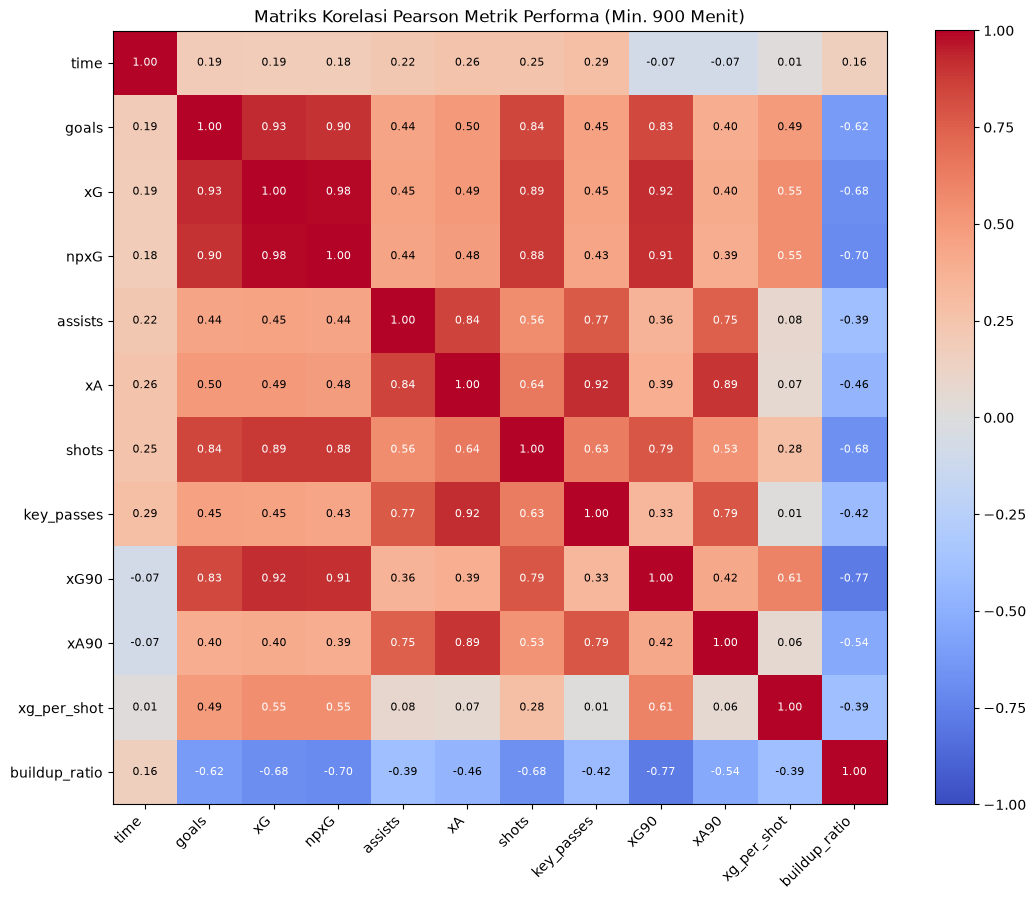

In [ ]:
eval_cols = ['time', 'goals', 'xG', 'npxG', 'assists', 'xA', 'shots', 'key_passes', 'xG90', 'xA90', 'xg_per_shot', 'buildup_ratio']
corr_matrix = df_min[eval_cols].corr()

fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(corr_matrix, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(eval_cols)))
ax.set_yticks(range(len(eval_cols)))
ax.set_xticklabels(eval_cols, rotation=45, ha='right')
ax.set_yticklabels(eval_cols)

for i in range(len(eval_cols)):
    for j in range(len(eval_cols)):
        ax.text(j, i, f"{corr_matrix.iloc[i, j]:.2f}", ha='center', va='center',
                color='white' if abs(corr_matrix.iloc[i, j]) > 0.5 else 'black', fontsize=8)

plt.colorbar(im)
plt.title('Matriks Korelasi Pearson Metrik Performa (Min. 900 Menit)')
plt.tight_layout()

## 7. Ringkasan Temuan

1. **Konsistensi Regresi ke Rerata Lintas 3 Musim:**
   Korelasi overperformance (`goals - xG`) pada kedua transisi musim berurutan bernilai rendah: **r = 0.016** (2023/2024 ke 2024/2025) dan **r = 0.092** (2024/2025 ke 2025/2026). Pada kohort 454 pemain yang bermain >= 900 menit selama 3 musim berturut-turut, overperformer tahun 2023 (Foden +7.69, Sørloth +7.57, Bellingham +6.03) dan overperformer tahun 2024 (Mbeumo +6.37, Orsolini +4.64, Sancet +4.54) seluruhnya mengalami penurunan signifikan menuju atau melampaui angka nol pada musim berikutnya. Hal ini membuktikan bahwa overperformance gol dalam rentang 1 musim tidak dapat diandalkan sebagai prediktor performa musim berikutnya.

2. **Disparitas Kualitas Tembakan (xG per Tembakan):**
   Terdapat variasi signifikan dalam pemilihan tembakan antar-pemain. Penyerang dengan selektivitas tinggi (seperti Thiago 0.294 xG/shot, Isak 0.283 xG/shot) menghasilkan nilai probabilitas gol hampir 30% per percobaan. Sebaliknya, pemain lini kedua tertentu (seperti Malinovskiy 0.025 xG/shot, Unai López 0.027 xG/shot) mengumpulkan volume tembakan tinggi dengan probabilitas konversi di bawah 3% per tembakan.

3. **Efisiensi Ancaman Non-Penalti per 90 Menit:**
   Standardisasi per 90 menit menunjukkan bahwa pemain dengan menit bermain terbatas (rotasi) dapat menghasilkan ancaman per satuan waktu yang setara atau melebihi pemain reguler. Alexander Sørloth (2024/2025) mencatatkan 1.24 npxG+xA per 90 dari 1.525 menit, melampaui pemain dengan menit bermain penuh.

4. **Diferensiasi Peran Penyerang Melalui Rasio Buildup:**
   Rasio `xGBuildup / xGChain` secara efektif membedakan profil taktis penyerang. Penyerang tipe *poacher* (Wood 0.06, Vardy 0.07, Kean 0.07) memiliki keterlibatan minimal pada fase persiapan serangan. Sebaliknya, penyerang bertipe *playmaking* memiliki rasio di atas 0.70, menandakan peran aktif dalam sirkulasi bola tim.

5. **Perbedaan Karakteristik Antar-Liga:**
   EPL mencatat rata-rata xG per tembakan tertinggi (0.113), mengindikasikan struktur serangan yang lebih sering menghasilkan peluang di dalam kotak penalti. La Liga secara konsisten mencatatkan jumlah kartu kuning dan kartu merah tertinggi di setiap musim (puncak 99 kartu merah di 2025/2026), mencerminkan frekuensi interupsi dan pelanggaran yang lebih tinggi dibanding EPL dan Serie A.